# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('yulu_rental.csv')

In [4]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [6]:
print("Shape:", df.shape)

Shape: (10886, 19)


In [7]:
display(df.head())
display(df.tail())

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,2012-12-19,19,51,2,Wednesday,2012,12,19
2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,2012-12-19,19,51,2,Wednesday,2012,12,20
2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,2012-12-19,19,51,2,Wednesday,2012,12,21
2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129,2012-12-19,19,51,2,Wednesday,2012,12,22
2012-12-19 23:00:00,4,0,1,1,13.12,16.665,66,8.9981,4,84,88,2012-12-19,19,51,2,Wednesday,2012,12,23


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10886 entries, 2011-01-01 00:00:00 to 2012-12-19 23:00:00
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   season       10886 non-null  int64  
 1   holiday      10886 non-null  int64  
 2   workingday   10886 non-null  int64  
 3   weather      10886 non-null  int64  
 4   temp         10886 non-null  float64
 5   atemp        10886 non-null  float64
 6   humidity     10886 non-null  int64  
 7   windspeed    10886 non-null  float64
 8   casual       10886 non-null  int64  
 9   registered   10886 non-null  int64  
 10  count        10886 non-null  int64  
 11  date         10886 non-null  object 
 12  day          10886 non-null  int32  
 13  week         10886 non-null  UInt32 
 14  weekday_num  10886 non-null  int32  
 15  weekday      10886 non-null  object 
 16  year         10886 non-null  int32  
 17  month        10886 non-null  int32  
 18  hour       

**Висновок:** Кількість даних у наборі: датасет містить 10 886 рядків (записів) та 19 колонок, без пропущених значень (10886 non-null у кожній колонці). Дані покривають період з 1 січня 2011 року (2011-01-01 00:00:00) до 19 грудня 2012 року (2012-12-19 23:00:00).   Рівень деталізації: дані мають погодинну деталізацію — кожен окремий рядок містить інформацію про кількість орендованих велосипедів та погодні умови за одну конкретну годину (крок індексу datetime становить 1 годину).   

## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


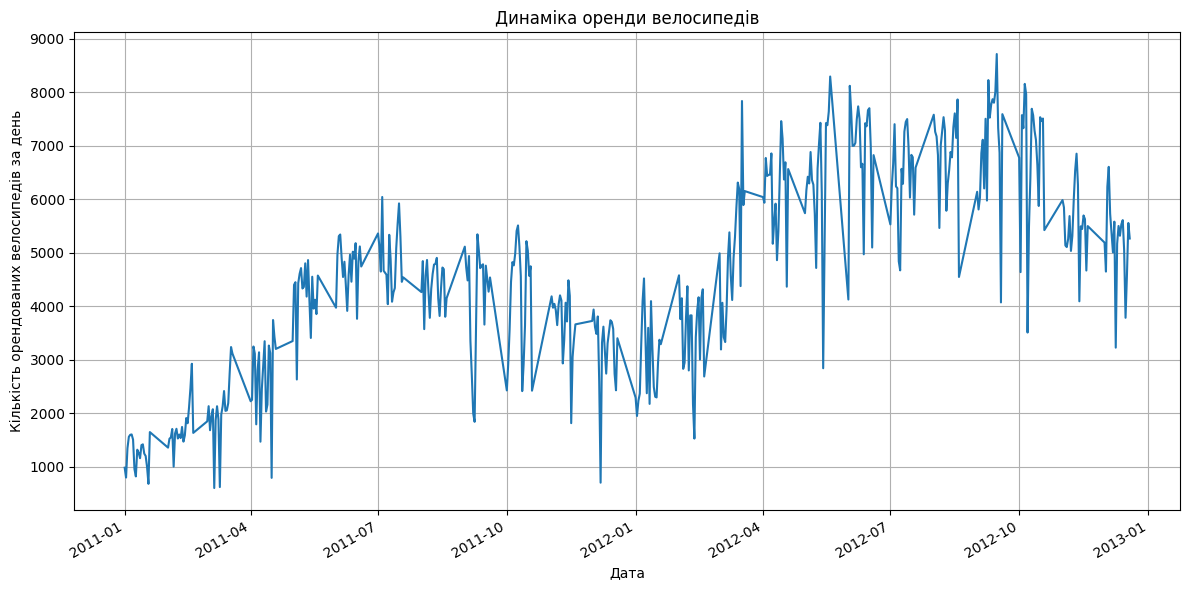

In [12]:
daily_rentals = (
    df.groupby('date')['count']
    .sum()
    .to_frame(name='count')
)

# Перетворюємо індекс на DatetimeIndex, щоб вісь дат коректно відображалася
daily_rentals.index = pd.to_datetime(daily_rentals.index)

# 2-3. Лінійний графік розміром (12, 6) із заголовком та сіткою
ax = daily_rentals.plot(
    kind='line',
    figsize=(12, 6),
    title='Динаміка оренди велосипедів',
    legend=False
)
ax.set_xlabel('Дата')
ax.set_ylabel('Кількість орендованих велосипедів за день')
ax.grid(True)

plt.tight_layout()
plt.show()

Сума оренд по роках:


,sum,mean
year,,
2011,781979,144.223349
2012,1303497,238.560944


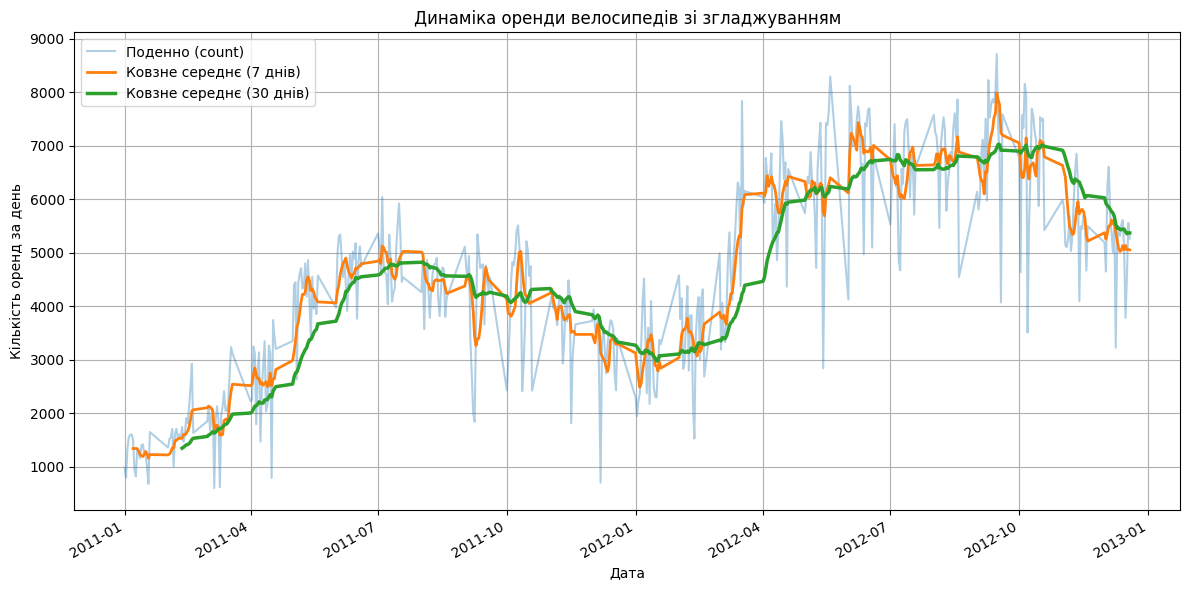

Топ-5 днів з НАЙБІЛЬШОЮ кількістю оренд:


,total_count,mean_temp,mean_humidity,max_weather,is_holiday,is_workingday
date,,,,,,
2012-09-15,8714,24.941667,50.166667,2,0,0
2012-05-19,8294,24.600000,45.625000,1,0,0
2012-09-09,8227,25.010000,54.750000,2,0,0
2012-10-05,8156,25.215000,62.750000,1,0,1
2012-06-02,8120,23.916667,54.916667,2,0,0


Топ-5 днів з НАЙМЕНШОЮ кількістю оренд:


,total_count,mean_temp,mean_humidity,max_weather,is_holiday,is_workingday
date,,,,,,
2011-03-06,605,15.437391,94.826087,3,0,0
2011-03-10,623,15.952727,0.000000,3,0,1
2011-01-18,683,8.883333,86.166667,2,0,1
2011-12-07,705,16.810000,97.041667,3,0,1
2011-04-16,795,17.664167,88.833333,3,0,0


In [13]:
print("Сума оренд по роках:")
display(df.groupby('year')['count'].agg(['sum', 'mean']))

# Згладжування "заломів" (7-денне та 30-денне ковзне середнє)
ax_smooth = daily_rentals['count'].plot(
    figsize=(12, 6),
    alpha=0.35,
    label='Поденно (count)'
)
daily_rentals['count'].rolling(7).mean().plot(
    ax=ax_smooth,
    linewidth=2,
    label='Ковзне середнє (7 днів)'
)
daily_rentals['count'].rolling(30).mean().plot(
    ax=ax_smooth,
    linewidth=2.5,
    label='Ковзне середнє (30 днів)'
)
ax_smooth.set_title('Динаміка оренди велосипедів зі згладжуванням')
ax_smooth.set_xlabel('Дата')
ax_smooth.set_ylabel('Кількість оренд за день')
ax_smooth.grid(True)
ax_smooth.legend()
plt.tight_layout()
plt.show()

# Пошук аномалій (найвищі та найнижчі дні + погода/статус дня)
daily_stats = df.groupby('date').agg(
    total_count=('count', 'sum'),
    mean_temp=('temp', 'mean'),
    mean_humidity=('humidity', 'mean'),
    max_weather=('weather', 'max'),
    is_holiday=('holiday', 'max'),
    is_workingday=('workingday', 'max')
)

print("Топ-5 днів з НАЙБІЛЬШОЮ кількістю оренд:")
display(daily_stats.nlargest(5, 'total_count'))

print("Топ-5 днів з НАЙМЕНШОЮ кількістю оренд:")
display(daily_stats.nsmallest(5, 'total_count'))

Висновки до Завдання 1
Чому графік має «заломи», чим це спричинено і як їх прибрати?   Графік з'єднує прямими відрізками дискретні денні суми орендованих велосипедів (count).   «Заломи» та різкі стрибки/провали виникають через щоденні коливання попиту: зміну погодних умов (weather, температуру temp, вологість humidity, швидкість вітру windspeed) та різницю між робочими днями й вихідними/святами (workingday, holiday).   Прибрати або згладити різкі «заломи» можна за допомогою ковзного середнього (наприклад, .rolling(7).mean() або .rolling(30).mean(), як показано на графіку зі згладжуванням), агрегації даних на вищому часовому рівні (потижнево чи щомісяця) або вибору іншого типу візуалізації для окремих відрізків.   
Які загальні тенденції ви бачите на графіку?   Загалом спостерігається зростання кількості оренд у 2012 році порівняно з 2011 роком: якщо у 2011 році денні значення здебільшого тримаються в межах приблизно 1 000–6 000 оренд, то у 2012 році рівень часто піднімається до 5 000–8 000+ оренд на день.   
Чи помітні якісь сезонні коливання?   Так, на графіку (особливо на 7-денному та 30-денному ковзному середньому) чітко видно сезонність: показники зростають навесні та влітку (наприклад, з квітня по вересень) і знижуються в холодніші місяці (взимку та пізньою осінню).   
Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?   Так, у даних є як різкі провали, так і пікові дні.   Найменші значення припадають на дні з несприятливою погодою — зокрема підвищеною вологістю (близько 88–97%) та гіршими погодними умовами (max_weather = 2 або 3, тобто туман/легкий дощ), а також низькою температурою (наприклад, 2011-01-18 із 683 орендами та середньою температурою ~8.88 °C, 2011-03-06 — 605 оренд, 2011-03-10 — 623 оренди).   Найвищі значення зафіксовано в теплу, комфортну погоду (mean_temp близько 23.9–25.2 °C, помірна вологість ~45.6–62.8%, max_weather = 1 або 2): піком став 2012-09-15 (8 714 оренд), далі йдуть 2012-05-19 (8 294), 2012-09-09 (8 227), 2012-10-05 (8 156) та 2012-06-02 (8 120).   


## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

In [ ]:
season_labels = {
    1: 'Q1 (1-й кв.)',
    2: 'Q2 (2-й кв.)',
    3: 'Q3 (3-й кв.)',
    4: 'Q4 (4-й кв.)'
}

# Середня кількість орендованих велосипедів за кварталами (DataFrame для DataFrame.plot)
season_mean = (
    df.groupby('season')['count']
    .mean()
    .rename(index=season_labels)
    .to_frame(name='mean_count')
)

ax = season_mean.plot(
    kind='bar',
    figsize=(10, 6),
    title='Середня кількість орендованих велосипедів за кварталами',
    legend=False,
    rot=0
)

ax.set_xlabel('Квартал')
ax.set_ylabel('Середня кількість оренд')
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Підписи значень над кожним стовпцем
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

# Невеликий запас зверху, щоб підпис над найвищим стовпцем не обрізався
ax.set_ylim(0, season_mean['mean_count'].max() * 1.12)

plt.tight_layout()
plt.show()

# Додатково: у скільки разів найбільше середнє більше за найменше
max_val = season_mean['mean_count'].max()
min_val = season_mean['mean_count'].min()
print(f"Максимум: {max_val:.2f}, Мінімум: {min_val:.2f}")
print(f"Відношення max / min: {max_val / min_val:.2f}x")

Висновки до Завдання 2 (за результатами)
У який квартал найбільша середня кількість оренди велосипедів?
Найбільша середня кількість орендованих велосипедів спостерігається у Q3 (3-й квартал) і становить 234.4 оренди за годину (точне значення — 234.42). Далі йдуть Q2 (215.3) та Q4 (199.0), а найменше середнє значення зафіксовано у Q1 (116.3 / 116.34).   
Як ви можете пояснити таку сезонну закономірність?
Попит на велопрокат безпосередньо пов'язаний із сезонними погодними умовами (температурою повітря, вологістю, опадами та комфортом поїздок):   У Q1 найнижчі температури та найменш комфортні умови для поїздок велосипедом, тому попит мінімальний.   У Q2 та Q3 погода тепліша й сприятливіша для пересування містом і прогулянок, через що попит зростає до пікових значень.   У Q4 середня кількість оренд дещо знижується порівняно з Q2–Q3, але залишається значно вищою за показник Q1.   
У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталами?
Середня кількість оренд у найпопулярнішому кварталі (Q3: 234.42) більша за найменш популярний квартал (Q1: 116.34) приблизно у 2.01 раза (тобто майже вдвічі).   

## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


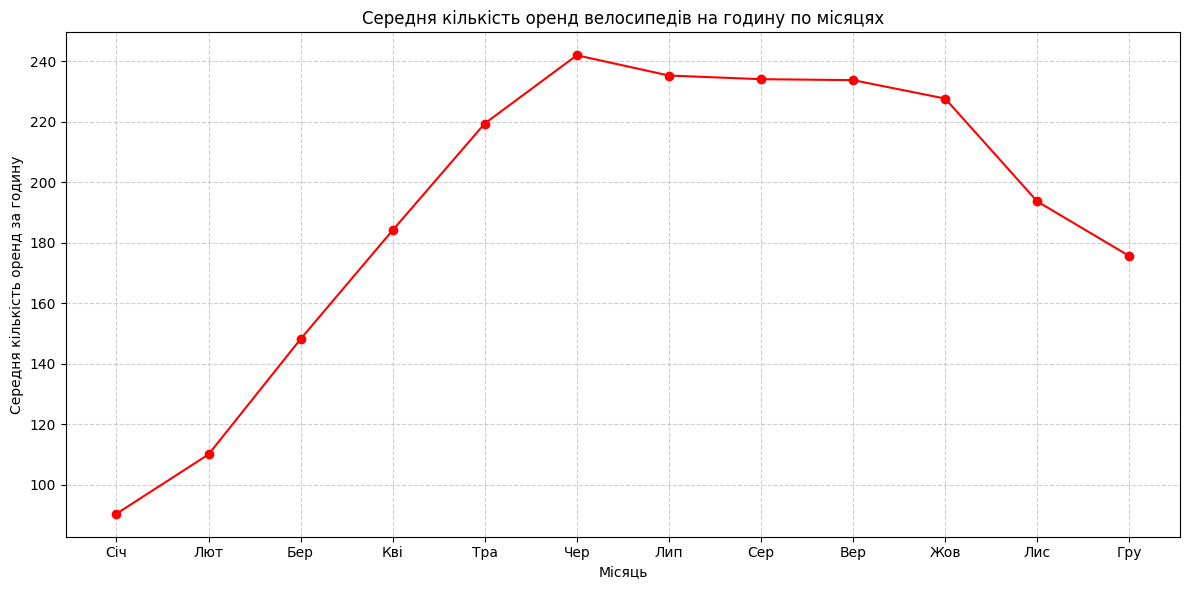

,mean_count,month_name
month,,
1,90.366516,Січ
2,110.003330,Лют
3,148.169811,Бер
4,184.160616,Кві
5,219.459430,Тра
6,242.031798,Чер
7,235.325658,Лип
8,234.118421,Сер
9,233.805281,Вер


In [14]:
month_labels = {
    1: 'Січ', 2: 'Лют', 3: 'Бер', 4: 'Кві',
    5: 'Тра', 6: 'Чер', 7: 'Лип', 8: 'Сер',
    9: 'Вер', 10: 'Жов', 11: 'Лис', 12: 'Гру'
}

# Середня кількість оренд на годину по місяцях (DataFrame для виклику DataFrame.plot)
monthly_mean = (
    df.groupby('month')['count']
    .mean()
    .reindex(range(1, 13))
    .to_frame(name='mean_count')
)

ax = monthly_mean.plot(
    kind='line',
    figsize=(12, 6),
    marker='o',
    color='red',
    title='Середня кількість оренд велосипедів на годину по місяцях',
    legend=False
)

ax.set_xlabel('Місяць')
ax.set_ylabel('Середня кількість оренд за годину')

# Чітко 12 поділок по осі OX — на кожен окремий місяць
ax.set_xticks(range(1, 13))
ax.set_xticklabels([month_labels[m] for m in range(1, 13)])

ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Додатково: точні значення по місяцях для зручності висновків
display(monthly_mean.assign(month_name=monthly_mean.index.map(month_labels)))

Висновки до Завдання 3

В які місяці спостерігається пік та спад оренди?   Пік оренди припадає на червень (Чер, 6-й місяць) — в середньому 242.03 оренди за годину. Високий рівень також утримується з травня по жовтень (близько 219.46–235.33 оренд за годину).   Спад оренди спостерігається взимку з мінімумом у січні (Січ, 1-й місяць) — лише 90.37 оренди за годину (далі йде лютий (Лют, 2-й місяць) із 110.00).   
Чи збігається ця закономірність з результатами з попереднього завдання?   Загальна логіка збігається: у Завданні 2 найменше середнє було в Q1 (116.34), куди входять січень, лютий і березень — саме тут найнижчі показники.   Водночас є цікавий нюанс із піковим місяцем: за кварталами лідером був Q3 (234.42), а за окремими місяцями найвище значення має червень (Чер, 242.03), який належить до Q2. Причина в тому, що в Q3 тримається стабільно високий рівень у липні (235.33), серпні (234.12) і вересні (233.81), що й виводить Q3 у лідери за середнім квартальним значенням.   
Як може вплинути клімат на оренду велосипедів протягом року?   Оскільки дані зібрано в Індії, річна динаміка залежить від місцевих кліматичних фаз: переходу від прохолоднішого зимового періоду (січень–лютий) до спекотнішої погоди навесні та початку літа, а згодом — до сезону мусонів (червень–вересень) та післямусонного періоду (жовтень–листопад).   Помірні температури та суха погода сприяють поїздкам, тоді як сильний холод, надмірна спека, підвищена вологість або дощі/зливи стримують активність користувачів.  

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

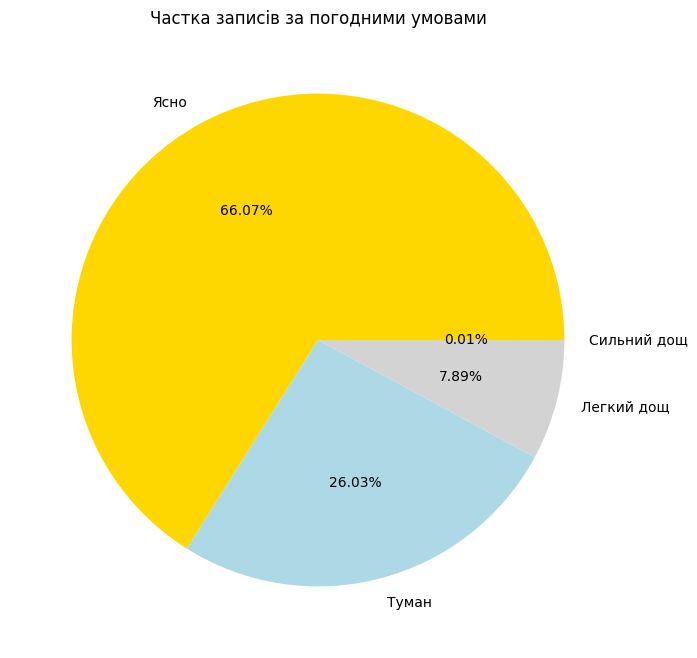

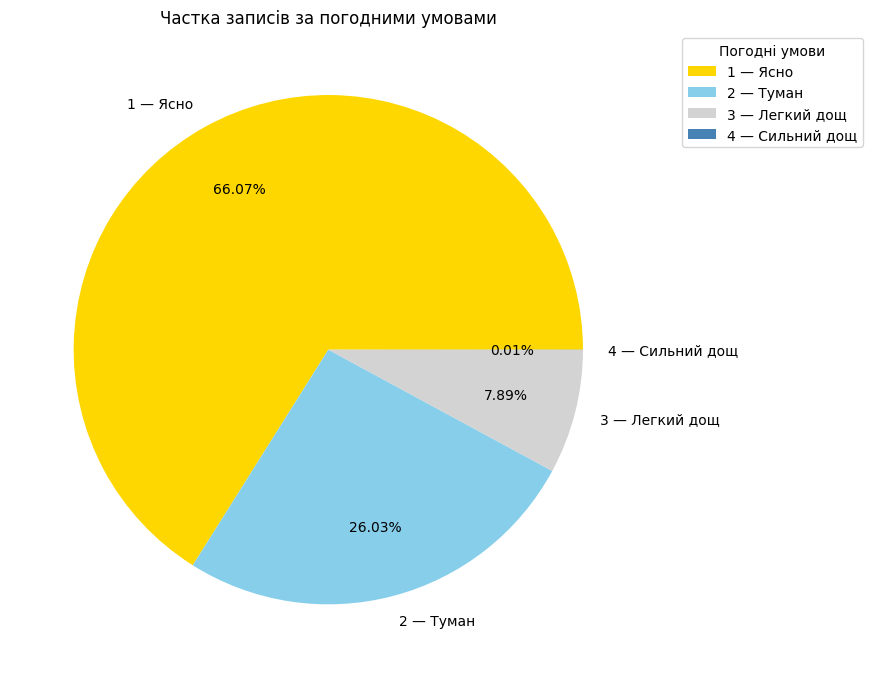

,count,share_%
weather,,
1 — Ясно,7192,66.066507
2 — Туман,2834,26.033437
3 — Легкий дощ,859,7.890869
4 — Сильний дощ,1,0.009186


In [15]:
weather_labels = {
    1: '1 — Ясно',
    2: '2 — Туман',
    3: '3 — Легкий дощ',
    4: '4 — Сильний дощ'
}

# Підрахунок кількості записів за кожною категорією погоди
weather_counts = (
    df['weather']
    .value_counts()
    .reindex([1, 2, 3, 4], fill_value=0)
    .rename(index=weather_labels)
    .to_frame(name='count')
)

# Власні кольори, відмінні від стандартних
custom_colors = ['#FFD700', '#87CEEB', '#D3D3D3', '#4682B4']

ax = weather_counts.plot(
    kind='pie',
    y='count',
    figsize=(9, 9),
    colors=custom_colors,
    autopct='%1.2f%%',
    pctdistance=0.72,
    startangle=0,
    legend=True,
    title='Частка записів за погодними умовами'
)

ax.set_ylabel('')  # Прибираємо зайву підпис 'count' ліворуч
ax.legend(
    labels=weather_counts.index,
    title='Погодні умови',
    loc='upper right',
    bbox_to_anchor=(1.35, 1.0)
)

plt.tight_layout()
plt.show()

# Додатково: точна кількість записів та частка у відсотках
weather_summary = weather_counts.copy()
weather_summary['share_%'] = (weather_summary['count'] / len(df)) * 100
display(weather_summary)

Яка погода переважає в датасеті?

У датасеті з великим відривом переважає ясна погода (weather = 1, «Ясно») — близько 66.07% усіх записів (майже дві третини спостережень). Друга за часткою категорія — «Туман» (weather = 2, близько 26.03%), а «Легкий дощ» (weather = 3) становить близько 7.89%.   
Чи є дні із сильним дощем? Яка їх частка?
Записи з категорією weather = 4 («Сильний дощ») у датасеті є, але їхня частка надзвичайно мала — близько 0.01% (одиничні часові записи з усього набору даних).   
Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?
Ясна й суха погода (1 — Ясно) забезпечує найбільший комфорт і безпеку для пересування, тому формує основний попит на оренду велосипедів. У разі погіршення погодних умов (туман, легкий або сильний дощ) поїздки стають менш комфортними та безпечнішими (гірша видимість, мокре покриття, дощ), через що кількість оренд помітно падає.

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

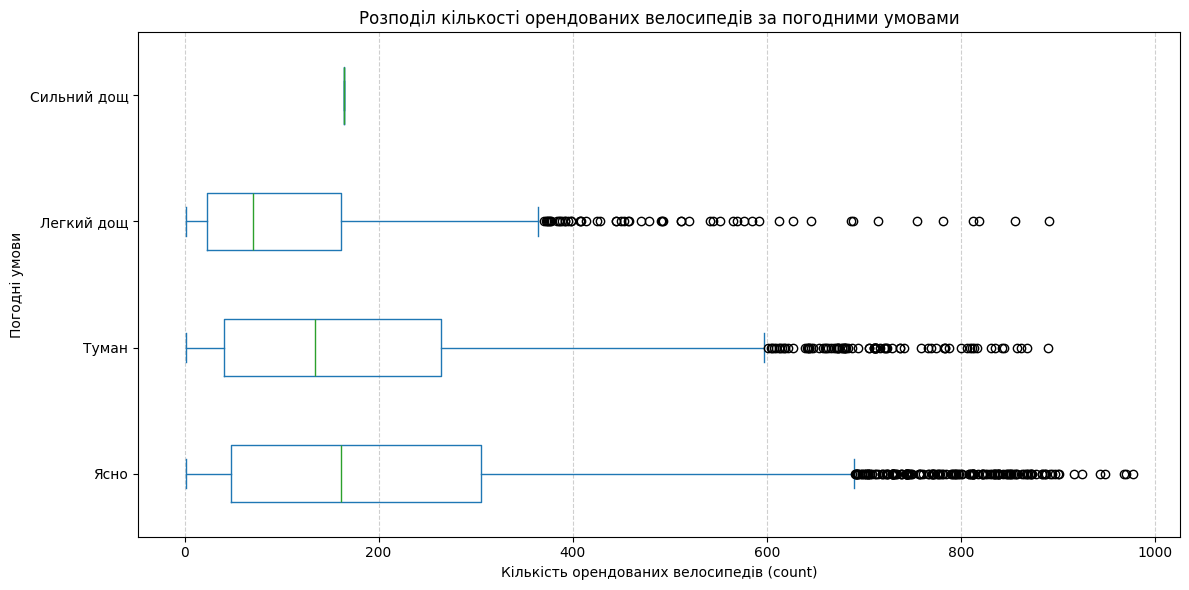

,weather,n_rows,min,Q1,median,Q3,IQR (Q3-Q1),max
0,Ясно,7192,1.0,48.0,161.0,305.0,257.0,977.0
1,Туман,2834,1.0,41.0,134.0,264.0,223.0,890.0
2,Легкий дощ,859,1.0,23.0,71.0,161.0,138.0,891.0
3,Сильний дощ,1,164.0,164.0,164.0,164.0,0.0,164.0


In [16]:
weather_names = {
    1: 'Ясно',
    2: 'Туман',
    3: 'Легкий дощ',
    4: 'Сильний дощ'
}

# Підготовка DataFrame, де кожен стовпець — окрема погодні умова з її значеннями 'count'
weather_box_df = (
    df.assign(weather_name=df['weather'].map(weather_names))
    .pivot(columns='weather_name', values='count')
)

# Фіксуємо порядок категорій (від найкращої погоди до найгіршої)
ordered_cols = ['Ясно', 'Туман', 'Легкий дощ', 'Сильний дощ']
weather_box_df = weather_box_df[[c for c in ordered_cols if c in weather_box_df.columns]]

ax = weather_box_df.plot(
    kind='box',
    vert=False,
    figsize=(12, 6),
    title='Розподіл кількості орендованих велосипедів за погодними умовами'
)

ax.set_xlabel('Кількість орендованих велосипедів (count)')
ax.set_ylabel('Погодні умови')
ax.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Додатково: медіана, IQR (Q3 - Q1), min, max та кількість записів для кожної погоди
stats = []
for col in weather_box_df.columns:
    s = weather_box_df[col].dropna()
    q1 = s.quantile(0.25)
    med = s.median()
    q3 = s.quantile(0.75)
    stats.append({
        'weather': col,
        'n_rows': len(s),
        'min': s.min(),
        'Q1': q1,
        'median': med,
        'Q3': q3,
        'IQR (Q3-Q1)': q3 - q1,
        'max': s.max()
    })
display(pd.DataFrame(stats))

Висновки до Завдання 5

При якій погоді найбільший розкид у кількості оренди?   Найбільший розкид спостерігається за погоди «Ясно» (1): міжквартильний розмах IQR становить 257.0 (Q1 = 48.0, Q3 = 305.0), а загальний діапазон від мінімуму до максимуму — від 1.0 до 977.0 (розмах max - min = 976.0).   Далі йдуть «Туман» (IQR = 223.0, від 1.0 до 890.0) та «Легкий дощ» (IQR = 138.0, від 1.0 до 891.0). Для категорії «Сильний дощ» (4) у вибірці лише 1 запис (164.0), тому IQR = 0.0.  
 Чи є викиди (outliers) в даних? При якій погоді?   Так, викиди є (позначені точками праворуч від верхнього «вуса»).   Вони спостерігаються при погодних умовах «Ясно», «Туман» та «Легкий дощ» — тобто в окремі години (наприклад, у години пік) кількість орендованих велосипедів значно перевищує типовий рівень для відповідної погоди.   
 При якій погоді медіанне значення оренди найвище?   Найвища медіана зафіксована за погоди «Ясно» — 161.0 оренд за годину.   З погіршенням погоди медіана послідовно знижується: «Туман» — 134.0, «Легкий дощ» — 71.0. (Одиночне спостереження для «Сильний дощ» має значення 164.0, але через обсяг у 1 запис воно не формує повноцінного розподілу.)   

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

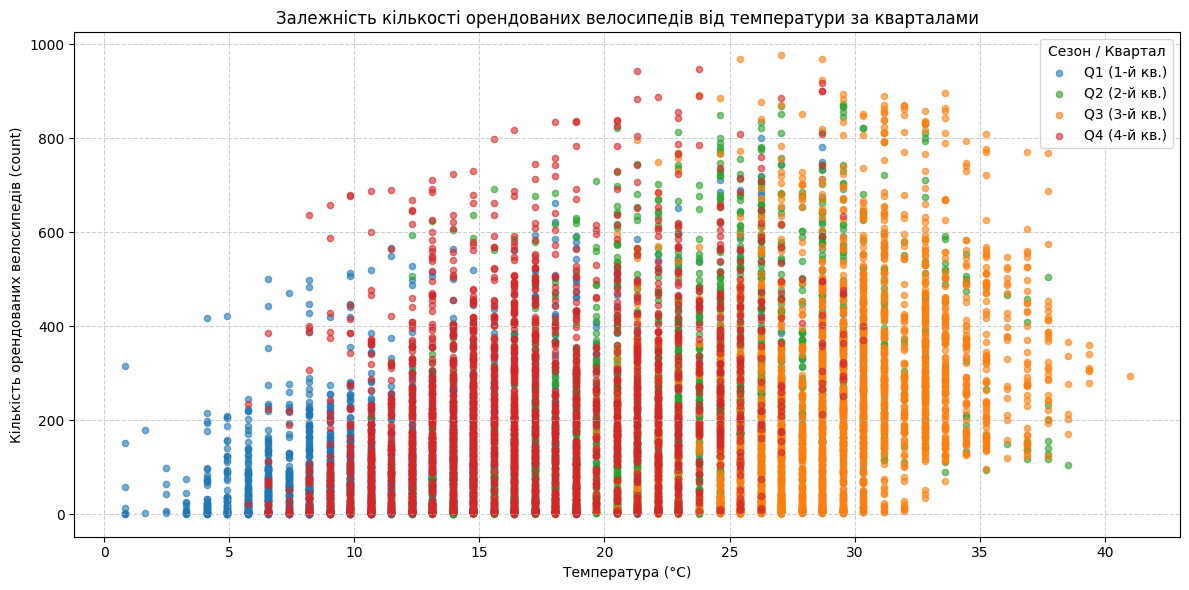

Загальна кореляція Пірсона (temp, count): 0.394453644967249

Кореляція по кварталах:
Q1 (1-й кв.): 0.4571
Q2 (2-й кв.): 0.4039
Q3 (3-й кв.): 0.3664
Q4 (4-й кв.): 0.3244


In [17]:
season_names = {
    1: 'Q1 (1-й кв.)',
    2: 'Q2 (2-й кв.)',
    3: 'Q3 (3-й кв.)',
    4: 'Q4 (4-й кв.)'
}

season_colors = {
    1: '#1f77b4',  # синій
    2: '#2ca02c',  # зелений
    3: '#ff7f0e',  # помаранчевий
    4: '#d62728'   # червоний
}

fig, ax = plt.subplots(figsize=(12, 6))

for s_code in [1, 2, 3, 4]:
    sub = df[df['season'] == s_code]
    sub.plot(
        kind='scatter',
        x='temp',
        y='count',
        ax=ax,
        color=season_colors[s_code],
        alpha=0.6,
        label=season_names[s_code]
    )

ax.set_title('Залежність кількості орендованих велосипедів від температури за кварталами')
ax.set_xlabel('Температура (°C)')
ax.set_ylabel('Кількість орендованих велосипедів (count)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(title='Сезон / Квартал')

plt.tight_layout()
plt.show()

# Додатково: коефіцієнт кореляції Пірсона між temp та count (загальний і по сезонах)
print("Загальна кореляція Пірсона (temp, count):", df['temp'].corr(df['count']))
print("\nКореляція по кварталах:")
for s_code, grp in df.groupby('season'):
    print(f"{season_names[s_code]}: {grp['temp'].corr(grp['count']):.4f}")

Висновки до Завдання 6

Чи є зв'язок між температурою та кількістю оренди? Який?   Так, зв'язок є — він позитивний (прямий) і помірний. Загальний коефіцієнт кореляції Пірсона між temp та count становить приблизно 0.39 (0.3945).   У межах окремих кварталів кореляція також додатна та помірна: найвища у Q1 (0.4571), далі йдуть Q2 (0.4039), Q3 (0.3664) та Q4 (0.3244).   На графіку видно, що при підвищенні температури (особливо до ~25–30 °C) верхня межа та загальний рівень кількості оренд зростають, хоча при однаковій температурі значення сильно розкидані — оскільки на попит впливають також погода (weather), вологість (humidity), час доби (hour) і тип дня (workingday, holiday). При дуже високих температурах (понад ~35 °C) пікові значення стають нижчими.

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?